In [2]:
import os
import fastf1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs("cache", exist_ok=True)
fastf1.Cache.enable_cache("cache")  # saves downloads so reruns are fast

Matplotlib is building the font cache; this may take a moment.


In [10]:
schedule = fastf1.get_event_schedule(2026)
print(schedule[["RoundNumber", "EventName", "EventDate"]]) # find the latest round that has happened
ROUND = 17 # change to the most recent completed round
session = fastf1.get_session(2026, ROUND,"R") # "R" = race
session.load()
print(session.event["EventName"])

core           INFO 	Loading data for Singapore Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '6'
core        WARNING 	Fixed incorrect tyre stint information for driver '14'


    RoundNumber                 EventName  EventDate
0             0        Pre-Season Testing 2026-02-13
1             0        Pre-Season Testing 2026-02-20
2             1     Australian Grand Prix 2026-03-08
3             2        Chinese Grand Prix 2026-03-15
4             3       Japanese Grand Prix 2026-03-29
5             4          Miami Grand Prix 2026-05-03
6             5       Canadian Grand Prix 2026-05-24
7             6         Monaco Grand Prix 2026-06-07
8             7      Barcelona Grand Prix 2026-06-14
9             8       Austrian Grand Prix 2026-06-28
10            9        British Grand Prix 2026-07-05
11           10        Belgian Grand Prix 2026-07-19
12           11      Hungarian Grand Prix 2026-07-26
13           12          Dutch Grand Prix 2026-08-23
14           13        Italian Grand Prix 2026-09-06
15           14        Spanish Grand Prix 2026-09-13
16           15     Azerbaijan Grand Prix 2026-09-26
17           16        Bahrain Grand Prix 2026

core        WARNING 	Fixed incorrect tyre stint information for driver '18'
core        WARNING 	Driver 3 completed the race distance 00:00.006000 before the recorded end of the session.
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['3', '16', '12', '1', '81', '44', '30', '27', '63', '6', '10', '87', '31', '55', '41', '14', '11', '23', '77', '18', '43', '5']


Singapore Grand Prix


In [13]:
laps = session.laps.pick_drivers(['30', '41']) # check the codes insession.results if this is empty
print(len(laps), "laps before cleaning")

clean = (laps
         .pick_wo_box()            # remove in-laps and out-laps (pit stops)
         .pick_track_status("1")   # green flag only: no safety car, VSC or yellows
         .pick_quicklaps())        # drop laps much slower than the fastest (traffic, mistakes)

clean = clean[clean["LapNumber"] > 1]   # lap 1 is a standing start, not representative
clean = pd.DataFrame(clean)             # plain DataFrame for easy maths
clean["LapTime_s"] = clean["LapTime"].dt.total_seconds()  # timedelta -> seconds

print(len(clean), "laps after cleaning")
print(clean[["Driver", "LapNumber", "Stint", "Compound", "TyreLife", "LapTime_s"]].head())

123 laps before cleaning
107 laps after cleaning
    Driver  LapNumber  Stint Compound  TyreLife  LapTime_s
590    LAW        2.0    1.0     SOFT       5.0     99.975
591    LAW        3.0    1.0     SOFT       6.0     99.606
592    LAW        4.0    1.0     SOFT       7.0     99.184
593    LAW        5.0    1.0     SOFT       8.0     99.058
594    LAW        6.0    1.0     SOFT       9.0     99.111


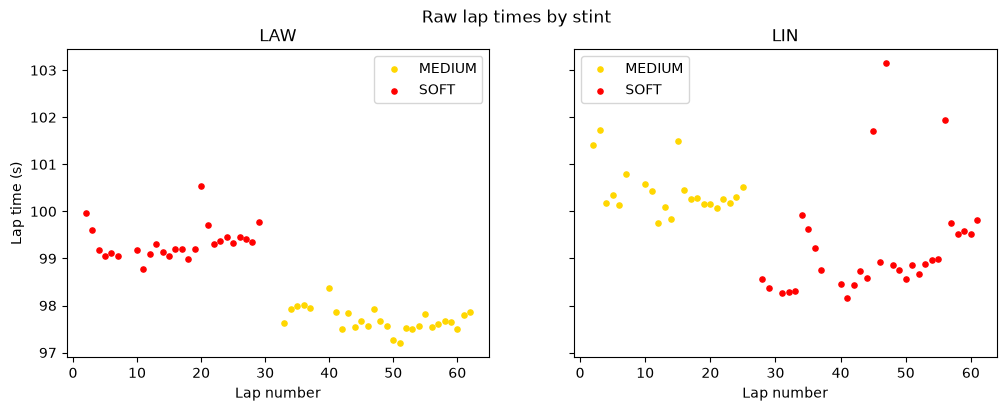

In [14]:
colors = {"SOFT": "red", "MEDIUM": "gold", "HARD": "gray"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, drv in zip(axes, ["LAW", "LIN"]):
    d = clean[clean["Driver"] == drv]
    for comp, g in d.groupby("Compound"):
        ax.scatter(g["LapNumber"], g["LapTime_s"], s=14,
                   color=colors.get(comp, "blue"), label=comp)
    ax.set_title(drv)
    ax.set_xlabel("Lap number")
    ax.legend()

axes[0].set_ylabel("Lap time (s)")
plt.suptitle("Raw lap times by stint")
plt.show()

In [15]:
K_FUEL = 0.03  # ASSUMPTION: seconds gained per lap as fuel burns off
clean["LapTime_fc"] = clean["LapTime_s"] + K_FUEL * (clean["LapNumber"] - 1)

In [16]:
results = []
for (drv, stint), g in clean.groupby(["Driver", "Stint"]):
    if len(g) < 6:
        continue  # too few laps to trust a slope
    fit = stats.linregress(g["TyreLife"], g["LapTime_fc"])
    results.append({
        "Driver": drv,
        "Stint": int(stint),
        "Compound": g["Compound"].iloc[0],
        "Laps": len(g),
        "Deg_s_per_lap": round(fit.slope, 3),
        "Low_95": round(fit.slope - 2 * fit.stderr, 3),
        "High_95": round(fit.slope + 2 * fit.stderr, 3),
        "R2": round(fit.rvalue ** 2, 2),
    })

deg = pd.DataFrame(results)
print(deg)

  Driver  Stint Compound  Laps  Deg_s_per_lap  Low_95  High_95    R2
0    LAW      1     SOFT    26          0.040   0.023    0.057  0.47
1    LAW      2   MEDIUM    28          0.018   0.008    0.028  0.34
2    LIN      1   MEDIUM    22          0.001  -0.027    0.030  0.00
3    LIN      2     SOFT    31          0.068   0.028    0.108  0.28


In [17]:
for k in [0.02, 0.03, 0.04]:
    slopes = {}
    for (drv, stint), g in clean.groupby(["Driver", "Stint"]):
        if len(g) < 6:
            continue
        t = g["LapTime_s"] + k * (g["LapNumber"] - 1)
        slopes[f"{drv} stint {int(stint)}"] = round(stats.linregress(g["TyreLife"], t).slope, 3)
    print(f"K_FUEL={k}:", slopes)

K_FUEL=0.02: {'LAW stint 1': np.float64(0.03), 'LAW stint 2': np.float64(0.008), 'LIN stint 1': np.float64(-0.009), 'LIN stint 2': np.float64(0.058)}
K_FUEL=0.03: {'LAW stint 1': np.float64(0.04), 'LAW stint 2': np.float64(0.018), 'LIN stint 1': np.float64(0.001), 'LIN stint 2': np.float64(0.068)}
K_FUEL=0.04: {'LAW stint 1': np.float64(0.05), 'LAW stint 2': np.float64(0.028), 'LIN stint 1': np.float64(0.011), 'LIN stint 2': np.float64(0.078)}


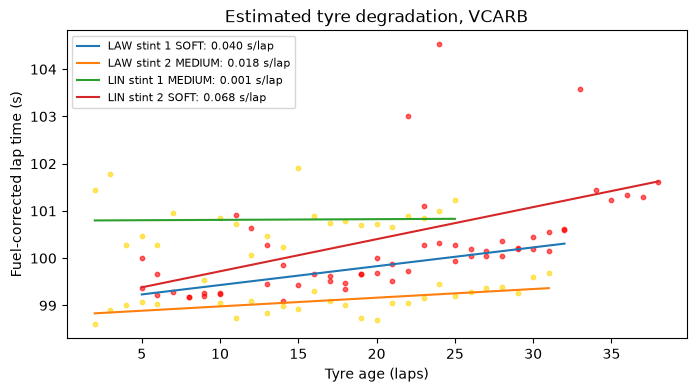

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
for (drv, stint), g in clean.groupby(["Driver", "Stint"]):
    if len(g) < 6:
        continue
    fit = stats.linregress(g["TyreLife"], g["LapTime_fc"])
    comp = g["Compound"].iloc[0]
    ax.scatter(g["TyreLife"], g["LapTime_fc"], s=10,
               color=colors.get(comp, "blue"), alpha=0.6)
    x = np.array([g["TyreLife"].min(), g["TyreLife"].max()])
    ax.plot(x, fit.intercept + fit.slope * x,
            label=f"{drv} stint {int(stint)} {comp}: {fit.slope:.3f} s/lap")

ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Fuel-corrected lap time (s)")
ax.set_title("Estimated tyre degradation, VCARB")
ax.legend(fontsize=8)
plt.show()

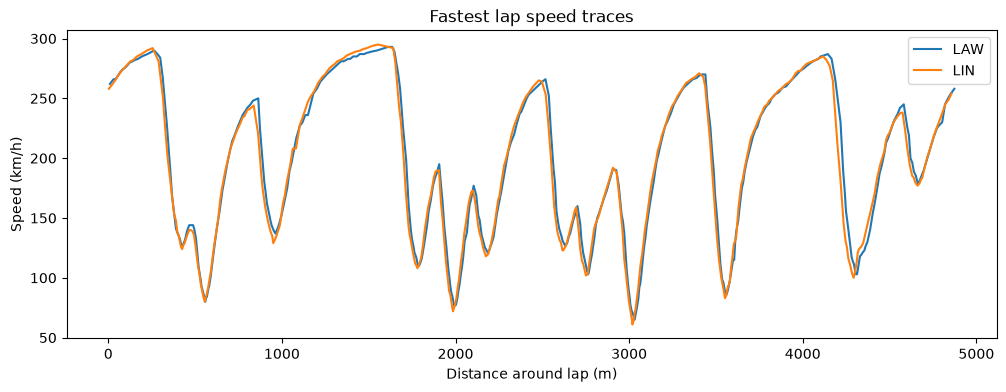

In [19]:
lap_law = session.laps.pick_drivers("30").pick_fastest()
lap_lin = session.laps.pick_drivers("41").pick_fastest()
tel_law = lap_law.get_car_data().add_distance()
tel_lin = lap_lin.get_car_data().add_distance()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tel_law["Distance"], tel_law["Speed"], label="LAW")
ax.plot(tel_lin["Distance"], tel_lin["Speed"], label="LIN")
ax.set_xlabel("Distance around lap (m)")
ax.set_ylabel("Speed (km/h)")
ax.set_title("Fastest lap speed traces")
ax.legend()
plt.show()

**Question:** how quickly did VCARB's tyres degrade at the 2026 Singapore Grand Prix?

**Method:** removed pit, safety car, lap 1 and traffic laps. Added back an assumed 0.03 s per lap fuel effect. Fitted a straight line of lap time vs tyre age for each stint.

**Findings:**
1. The soft degraded fastest: about 0.04 s per lap for Lawson (range 0.023 to 0.057) and about 0.07 s per lap for Lindblad (range 0.028 to 0.108).
2. The medium held up much better: about 0.02 s per lap for Lawson, and no measurable wear for Lindblad (range includes zero).
3. Changing the fuel assumption from 0.02 to 0.04 did not change the ranking of stints. It did shift every value by the same amount, so the absolute numbers depend on the fuel guess.

**Limitations:** fuel effect is assumed, not measured. A few slow laps (likely traffic) remain and inflate Lindblad's soft estimate. Straight lines can't capture a tyre cliff. Track evolution isn't removed. One race only.